# Tutorial 6c: Roughness, Scattering and Extended Sources

**In this tutorial:** physical effects beyond ideal surfaces, namely micro-roughness, scattering with BSDF models and extended (non-point) sources.


This tutorial demonstrates how surface roughness and scattering can be configured on surfaces in Optiland. We will compare singlets with the following scattering properties assigned:

- No scattering
- Gaussian Scattering
- Lambertian Scattering

The scattering model is defined via the Bidirectional Scattering Distribution Function, or BSDF.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from optiland import optic, scatter

Preparation

We first define a generic singlet class that accepts a bsdf as an input. In this example, we assign the scattering only to the rear surface.

In [2]:
class SingletConfigurable(optic.Optic):
    def __init__(self, bsdf):
        super().__init__()

        # add surfaces
        self.surfaces.add(index=0, radius=np.inf, thickness=np.inf)
        self.surfaces.add(
            index=1,
            thickness=7,
            radius=50,
            is_stop=True,
            material="N-SF11",
        )
        self.surfaces.add(index=2, thickness=50, bsdf=bsdf)  # <-- add bsdf here
        self.surfaces.add(index=3)

        # add aperture
        self.set_aperture(aperture_type="EPD", value=25.4)

        # add field
        self.fields.set_type(field_type="angle")
        self.fields.add(y=0)
        self.fields.add(y=10)
        self.fields.add(y=14)

        # add wavelength
        self.wavelengths.add(value=0.48613270)
        self.wavelengths.add(value=0.58756180, is_primary=True)
        self.wavelengths.add(value=0.65627250)

        self.updater.image_solve()  # solve for image plane

Let's also define a helper function to plot a 2D distribution of rays intersection points.

In [3]:
def plot_ray_distribution(rays, bins=128):
    x = rays.x
    y = rays.y
    i = rays.i

    plt.hist2d(x, y, weights=i, bins=bins, cmap="viridis")
    plt.colorbar()
    plt.xlabel("X (mm)")
    plt.ylabel("Y (mm)")
    plt.title("2D Ray Distribution on Image Plane")
    plt.show()

1. Singlet #1 - No Surface Scattering

The first singlet we analyze will have no scattering applied. Let's first define the lens and draw it.

In [4]:
singlet_no_scatter = SingletConfigurable(bsdf=None)

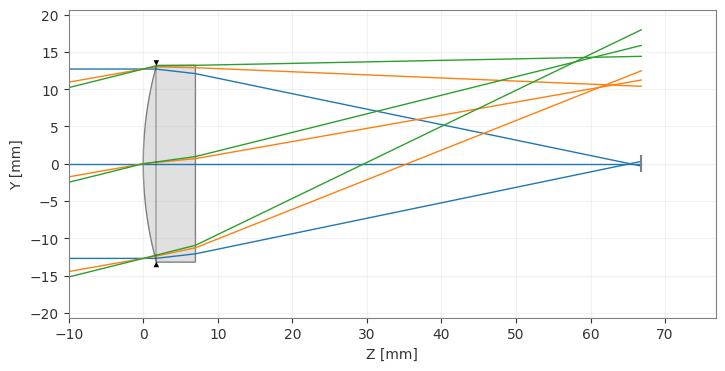

(<Figure size 1000x400 with 1 Axes>, <Axes: xlabel='Z [mm]', ylabel='Y [mm]'>)

In [5]:
singlet_no_scatter.draw()

Let's trace 1 million random rays through the lens at the on-axis field point and look at the distribution.

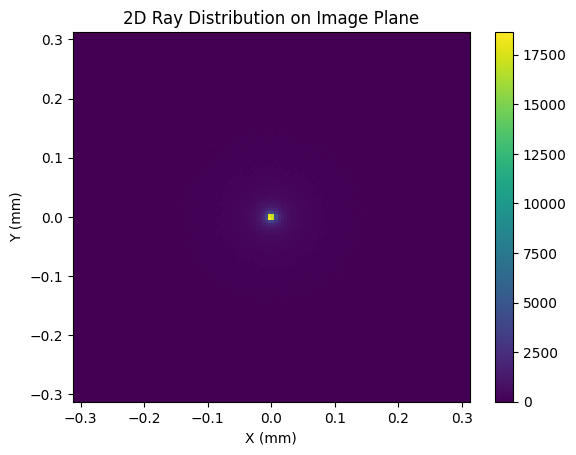

In [6]:
rays = singlet_no_scatter.trace(
    Hx=0,
    Hy=0,
    wavelength=0.58756180,
    num_rays=1_000_000,
    distribution="random",
)

plot_ray_distribution(rays, bins=128)

As we can see, the energy is largely located at the origin on the image plane. Let's see how this is implacted when scattering is introduced.

2. Singlet #2 - Gaussian Scattering

Gaussian scattering is defined by a 2D Gaussian distribution with a user-defined sigma (std. dev.) value. The larger the value of sigma, the closer the scattering model comes to Lambertian. We define a GaussianBSDF model with a sigma value of 0.01 and generate a new singlet:

In [7]:
bsdf = scatter.GaussianBSDF(sigma=0.01)
singlet_gaussian = SingletConfigurable(bsdf=bsdf)

Again, we trace 1 million rays and view the distribution at the image plane:

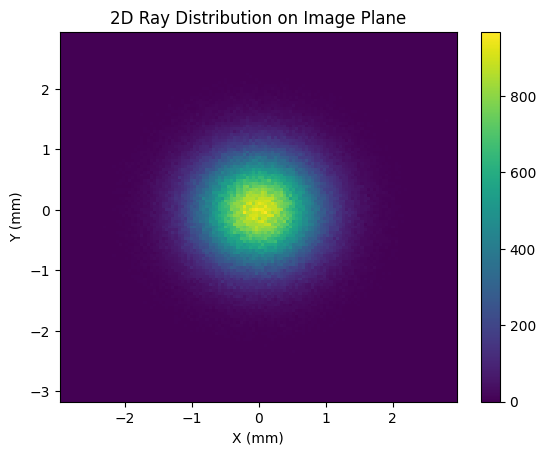

In [8]:
rays = singlet_gaussian.trace(
    Hx=0,
    Hy=0,
    wavelength=0.58756180,
    num_rays=1_000_000,
    distribution="random",
)

plot_ray_distribution(rays)

The image size has blurred significantly in comparison to the no-scattering case. Note that the plot axis spans a larger range here as well.

3. Singlet #3 - Lambertian Scattering

Lambertian scattering implies that the surface scatters incident light uniformly in all directions. Diffuse surfaces can be considered approximately Lambertian. To model a Lambertian scatterer in Optiland, we simply define the LambertianBSDF model and pass it to our singlet:

In [9]:
bsdf = scatter.LambertianBSDF()
singlet_lambertian = SingletConfigurable(bsdf=bsdf)

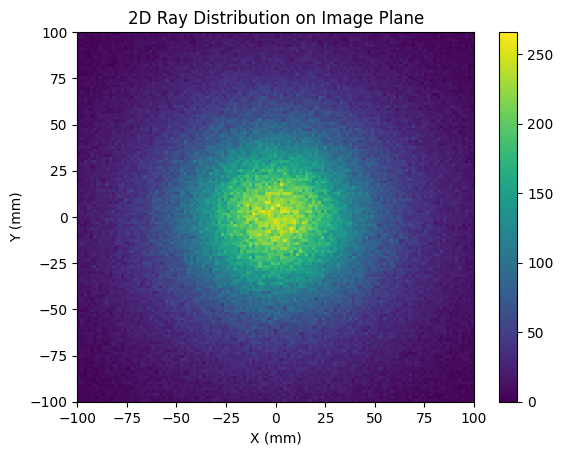

In [10]:
rays = singlet_lambertian.trace(
    Hx=0,
    Hy=0,
    wavelength=0.58756180,
    num_rays=1_000_000,
    distribution="random",
)

plot_ray_distribution(rays, bins=np.linspace(-100, 100, 128))

In this case, we are plotting the image plane over a significantly larger area, from -100 mm to 100 mm. Clearly, the Lambertian scatter model has dramatically increased the spot size at the image plane.

4. Conclusions:

- We introduced two BSDF scatter models: Gaussian and Lambertian.
- Scatter models can be used to model and understand the impact of manufacturing defects, such as surface roughness on optical surfaces.


---
## Part 2: Extended Source Modeling



In [11]:
import optiland.backend as be
from optiland.optic import Optic, ExtendedSourceOptic
from optiland.sources import SMFSource
from optiland.analysis import IncoherentIrradiance
from optiland.physical_apertures import RectangularAperture

## 1. Define the Optical System

First, we define the Beam Shaping Singlet system. This system is designed to transform a Gaussian beam into a flat-top profile.

In [12]:
gaussian_beam_waist = 5.0  # in mm
wavelength_um = 0.55  # in µm

# Forbes QBFS surface parameters
forbes_terms = {
    0: 0.5414,
    1: 0.6689,
    2: 0.3409,
    3: -0.0537,
    4: -0.3960,
    5: -0.2991,
    6: 0.3921,
}
forbes_norm_radius = 30.3636
top_hat_radius = 25.0

# Create the Optic
lens = Optic()
lens.set_aperture(
    aperture_type="EPD", value=gaussian_beam_waist * 6
)
lens.wavelengths.add(value=wavelength_um, is_primary=True)
lens.fields.set_type(field_type="angle")
lens.fields.add(y=0.0)

# Add surfaces
lens.surfaces.add(index=0, thickness=be.inf)
lens.surfaces.add(
    index=1,
    thickness=20.0,
    is_stop=True,
    aperture=RectangularAperture(
        x_min=-15,
        x_max=15,
        y_min=-15,
        y_max=15,
    ),
)
lens.surfaces.add(
    index=2,
    surface_type="forbes_qbfs",
    radius=5.7410,
    conic=-2.3165,
    thickness=15.0,
    material="N-BK7",
    radial_terms=forbes_terms,
    norm_radius=forbes_norm_radius,
    aperture=30.0,
)
lens.surfaces.add(
    index=3, 
    surface_type="standard", 
    radius=be.inf, 
    thickness=70.0, 
    material="air"
)
lens.surfaces.add(
    index=4,
    aperture=RectangularAperture(
        x_min=-top_hat_radius * 1.1,
        x_max=top_hat_radius * 1.1,
        y_min=-top_hat_radius * 1.1,
        y_max=top_hat_radius * 1.1,
    ),
)

> **Note on Normalization Radius (`norm_radius`)**:
>
> In `optiland`, when you explicitly provide normalization parameters (like `norm_radius` for Forbes/Zernike surfaces, or `norm_x`/`norm_y` for Chebyshev surfaces) during geometry initialization, the surface's `normalization_mode` is automatically set to `'manual'`.
>
> This means the radius is **locked** to your provided value and will not be automatically scaled during paraxial updates. If you omit the normalization parameters, the `normalization_mode` defaults to `'auto'`, and the normalization radius will dynamically scale to $1.25 \times \text{semi-aperture}$.

## 2. Setup Extended Source

We use `SMFSource` to represent a collimated Gaussian source. 

**Note on Collimation:** To approximate a collimated source using `SMFSource`, we set the divergence angle to an extremely small value (e.g., `1e-10` degrees).
The Mode Field Diameter (MFD) determines the spatial extent of the beam. Here we set it to $2 × \text{waist} = 10\text{ mm} = 10000\text{ µm}$.

In [13]:
# MFD is in microns. 2 * waist (5mm) = 10mm = 10000um
mfd_microns = gaussian_beam_waist * 2 * 1000

# Create the source
source = SMFSource(
    mfd_um=mfd_microns,
    wavelength_um=wavelength_um,
    divergence_deg_1e2=1e-10,  # Virtually zero divergence for collimation
    total_power=1.0,
    position=(0, 0, 0)
)

# Wrap the optic with the source
ext_optic = ExtendedSourceOptic(lens, source)

print(source)

SMFSource(mfd=10000.0µm, divergence=1e-10°, wavelength=0.55µm, power=1.0W, mode=extended, position=(0.0, 0.0, 0.0))


## 3. Visualization

We can now draw the optical system with the source rays traced through it. The `draw` method of `ExtendedSourceOptic` handles this automatically.

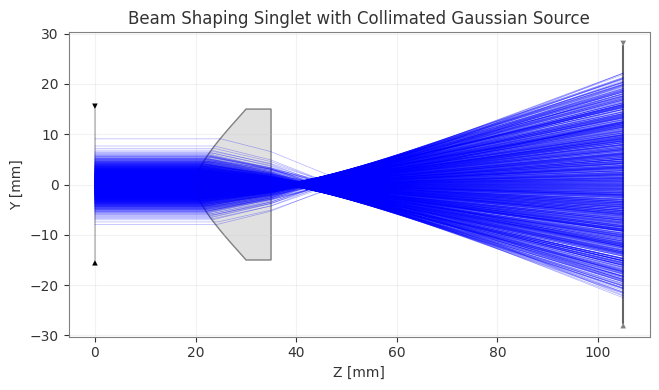

In [14]:
fig, ax = ext_optic.draw(num_rays=1000, title="Beam Shaping Singlet with Collimated Gaussian Source")

## 4. Irradiance Analysis

Finally, we calculate and visualize the irradiance at the image plane. We trace a larger number of rays for better resolution and use `IncoherentIrradiance`.

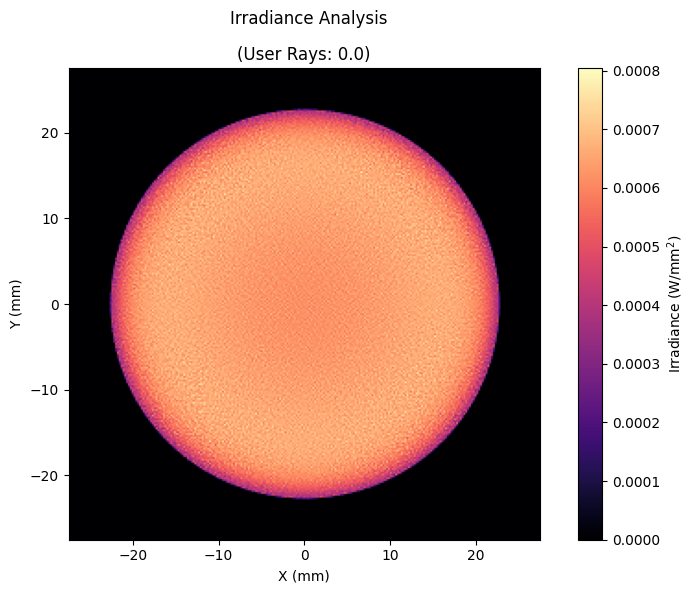

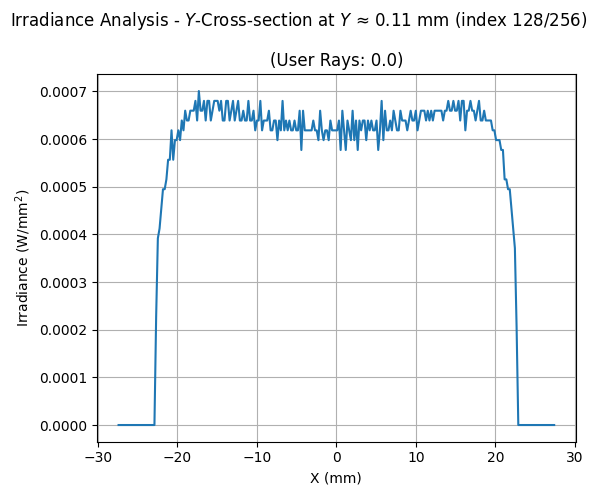

(<Figure size 600x500 with 1 Axes>,
 array([[<Axes: title={'center': '(User Rays: 0.0)'}, xlabel='X (mm)', ylabel='Irradiance (W/mm$^2$)'>]],
       dtype=object))

In [15]:
# Compute and plot irradiance
analysis = IncoherentIrradiance(lens, source=source, num_rays=1_000_000, detector_surface=-1, res=(256, 256))
analysis.view(figsize=(8, 6), cmap="magma", normalize=False)
analysis.view(cross_section=("cross-y", 128), normalize=False)